# The human growth model

We apply `elicito` to the Preece-Baines growth model of
Hartmann et al. (2020, PMLR 124).

## Imports

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

from functools import partial
from typing import Any

import numpy as np
import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The oracle table

The raw elicited thresholds are not published. Each table gives only the
resulting prior, as $E[\cdot]$ and $V(\cdot)$ per parameter. We treat the
printed *predictive* prior as the oracle.

Seven variances are censored: five for $s_0$, one for $h_1$ and one for
$s_1$. Half the bound is the obvious substitute, but it fails for $s_0$. The
bound of user 1 equals the mean of $s_0$. Half of it gives a standard
deviation of 0.22, more than twice the mean, and such a prior puts a large
part of its mass on a curve with a **negative** stature at birth. The 10%
quantile of the simulated stature at age 0 is then $-311$ cm.

So we take the smaller of two values: half the bound, and the variance of a
standard deviation of a quarter of the mean. The result stays below every
printed bound, and every simulated stature is positive.

| user | parameter | mean | printed | half the bound | our substitute |
| :-- | :-- | --: | --: | --: | --: |
| 1 | $s_0$ | 0.1 | < 0.1 | 0.05 | 0.000625 |
| 2 | $s_0$ | 0.04 | < 0.01 | 0.005 | 0.0001 |
| 3 | $s_0$ | 0.07 | < 0.001 | 0.0005 | 0.00030625 |
| 4 | $h_1$ | 174.5 | < 0.01 | 0.005 | 0.005 |
| 4 | $s_0$ | 0.1 | < 0.01 | 0.005 | 0.000625 |
| 5 | $s_0$ | 0.1 | < 0.01 | 0.005 | 0.000625 |
| 5 | $s_1$ | 3.4 | < 0.01 | 0.005 | 0.005 |

The table is stated in the parameters $\delta_h$ and $\delta_s$ of the next
section, not in $h_1$ and $s_1$. Under independence, $E[\delta] = E[h_1] -
E[h_0]$ and $V(\delta) = V(h_1) + V(h_0)$.

In [2]:
# user 1: Table 1 of Hartmann et al. (2020)
# users 2 to 5: Tables 1 to 4 of the supplement
PREDICTIVE_PRIOR = {
    # parameter: (mean, variance) per user
    # the order must match the unpacking in GrowthModel.__call__
    "hts": [(162.8, 4.2), (153.73, 1.6), (148.8, 1.86), (162.8, 0.02), (162.6, 0.85)],
    # user 4: the printed variance of h1 is censored; see the text above
    "dh": [(11.7, 5.0), (38.01, 5.92), (28.34, 5.54), (11.7, 0.025), (11.8, 1.76)],
    "ts": [(13.4, 0.01), (15.9, 0.7), (11.31, 0.21), (14.7, 0.9), (14.6, 0.02)],
    # the printed variance of s0 is censored; see the text above
    "s0": [
        (0.1, 0.000625),
        (0.04, 0.0001),
        (0.07, 0.00030625),
        (0.1, 0.000625),
        (0.1, 0.000625),
    ],
    # user 5: the printed variance of s1 is censored as well
    "ds": [
        (3.2, 0.26),
        (1.96, 4.3001),
        (4.47, 37.83030625),
        (1.5, 1.700625),
        (3.3, 0.005625),
    ],
    "b": [(15.79, 12.9), (61.4, 111.4), (18.4, 12.5), (14.5, 14.3), (17.8, 17.8)],
}

## The model

The growth curve is equation 25 of the supplement:

$$
h(t; \theta) = h_1 - \frac{2 (h_1 - h_0)}
{\exp[s_0 (t - t_s)] + \exp[s_1 (t - t_s)]}
$$

The model needs $0 < h_0 < h_1$ and $0 < s_0 < s_1$, to identify it and to
keep it physically plausible. We follow Manderson and Goudie (2026) and
learn the differences

$$
\delta_h = h_1 - h_0, \qquad \delta_s = s_1 - s_0
$$

instead. Then $h_0$, $\delta_h$, $s_0$ and $\delta_s$ share one positivity
constraint, and a LogNormal prior satisfies it.

The model learns six parameters, in this order:

- $h_{t_s}$ (`hts`), the stature at $t_s$, in cm. The curve passes through
  this point, so it fixes the height at the turn.
- $\delta_h$ (`dh`), the growth that is left after $t_s$, in cm. The adult
  height is $h_1 = h_{t_s} + \delta_h$.
- $t_s$ (`ts`), the age at peak growth velocity, in years. It shifts the
  curve along the age axis.
- $s_0$ (`s0`), the slow rate constant, in 1/year. Its term dominates the
  denominator before $t_s$, so $s_0$ sets the childhood growth rate.
- $\delta_s$ (`ds`), the extra rate of the second constant, in 1/year, with
  $s_1 = s_0 + \delta_s$. The $s_1$ term dominates after $t_s$. A large
  $\delta_s$ gives a short and sharp adolescent spurt.
- $b$ (`b`), the shape of the Weibull likelihood. It sets the spread of one
  stature around its mean, and a large $b$ gives a small spread. The
  coefficient of variation is 7.8% at the oracle mean $b = 15.8$ of user 1.

The remedy is not a proof. Manderson and Goudie note that the denominator
can still be very small, which gives a negative height.

They also constrain $t_s$ to the range of the observed ages. We follow them.
$t_s$ has a Normal prior truncated to $[0, T]$, where $T$ is the oldest
queried age. Its location is bounded to the same range, so the unconstrained
hyperparameter is a logit and $T \cdot \mathrm{sigmoid}$ maps it back.

The bound is still not enough. Measured on 51200 draws from the true prior
of user 1, the mean height at age 0 was negative for 4.5% of them. So the
model passes the predicted mean through a softplus. Above 20 cm a softplus
is the identity to within $10^{-9}$, and a height is positive by
construction.

The expert sees the stature at four ages.

In [3]:
AGES = tf.constant([0.0, 2.5, 10.0, 17.5])
T_MAX = float(AGES[-1])


def bounded_ts(loc: Any, scale: Any) -> Any:
    """
    Build the prior of the age at peak velocity

    A Normal truncated to the range of the queried ages.

    Parameters
    ----------
    loc, scale
        location and scale of the untruncated Normal

    Returns
    -------
    :
        truncated Normal on ``[0, T_MAX]``
    """
    return tfd.TruncatedNormal(loc=loc, scale=scale, low=0.0, high=T_MAX)


class GrowthModel:
    """
    Preece-Baines generative model
    """

    # `elicito` calls this inside a compiled forward pass. AutoGraph would
    # then rewrite the body, and it finds the body by file and line. A cell
    # of a notebook has no source file in a worker process of
    # the parallel `seeds`, so AutoGraph rewrites the wrong function there.
    # This model has no Python branch to rewrite, so we switch it off.
    @tf.autograph.experimental.do_not_convert
    def __call__(
        self, prior_samples: Any, ages: Any, seed: Any = None
    ) -> dict[str, Any]:
        """
        Compute target quantities from generative model

        Parameters
        ----------
        prior_samples
            prior samples

        ages
            ages at which the expert is queried

        seed
            stateless seed for the likelihood draw. `elicito` passes it
            because this signature names it. The draw then repeats without
            `tf.random.set_seed`, which the compiled forward pass cannot use.

        Returns
        -------
        :
            dictionary with target quantities
        """
        # shape (B, S, 1) each, to broadcast over the ages
        hts, dh, ts, s0, ds, b = (
            tf.expand_dims(prior_samples[:, :, i], -1) for i in range(6)
        )

        # back to the parameters of the curve; both differences are positive
        h1 = hts + dh
        s1 = s0 + ds

        # growth curve, supplement equation 25. The denominator
        # exp(a) + exp(b) overflows for a large s1, and its gradient is then
        # inf * 0 = NaN. exp(-logsumexp(a, b)) is the same value with a finite
        # gradient.
        exponents = tf.stack([s0 * (ages - ts), s1 * (ages - ts)], axis=-1)
        epred = h1 - 2 * (h1 - hts) * tf.exp(
            -tf.math.reduce_logsumexp(exponents, axis=-1)
        )

        # The curve dips below zero for an extreme draw, and a height cannot.
        # softplus equals the identity to within 1e-9 above 20 cm, so it
        # changes nothing in the plausible range.
        epred = tf.nn.softplus(epred)

        # Weibull in the mean-variance form, supplement equation 24
        likelihood = tfd.Weibull(
            concentration=b,
            scale=epred / tf.exp(tf.math.lgamma(1.0 + 1.0 / b)),
        )
        ypred = likelihood.sample(seed=seed)

        y_t0, y_t1, y_t2, y_t3 = (ypred[:, :, i] for i in range(4))

        return dict(
            y_t0=y_t0, y_t1=y_t1, y_t2=y_t2, y_t3=y_t3, ypred=ypred, epred=epred
        )

## The oracle

We match a LogNormal to each growth parameter by moments, and a Gamma to
the Weibull shape $b$.

In [4]:
def oracle(user: int) -> dict[str, Any]:
    """
    Build the ground-truth prior of one user

    Parameters
    ----------
    user
        user number, 1 to 5

    Returns
    -------
    :
        dictionary with one distribution per parameter
    """
    truth = dict()
    for name, table in PREDICTIVE_PRIOR.items():
        m, v = table[user - 1]
        if name == "b":
            truth[name] = tfd.Gamma(concentration=m**2 / v, rate=m / v)
        elif name == "ts":
            # the bounds are far from the mass, so the moments are the
            # untruncated ones to machine precision for user 1
            truth[name] = bounded_ts(loc=float(m), scale=float(np.sqrt(v)))
        else:
            sigma2 = np.log(1.0 + v / m**2)
            truth[name] = tfd.LogNormal(
                loc=float(np.log(m) - sigma2 / 2.0), scale=float(np.sqrt(sigma2))
            )
    return truth


oracle(user=1)

{'hts': <tfp.distributions.LogNormal 'LogNormal' batch_shape=[] event_shape=[] dtype=float32>,
 'dh': <tfp.distributions.LogNormal 'LogNormal' batch_shape=[] event_shape=[] dtype=float32>,
 'ts': <tfp.distributions.TruncatedNormal 'TruncatedNormal' batch_shape=[] event_shape=[] dtype=float32>,
 's0': <tfp.distributions.LogNormal 'LogNormal' batch_shape=[] event_shape=[] dtype=float32>,
 'ds': <tfp.distributions.LogNormal 'LogNormal' batch_shape=[] event_shape=[] dtype=float32>,
 'b': <tfp.distributions.Gamma 'Gamma' batch_shape=[] event_shape=[] dtype=float32>}

## Model parameters

The hyperparameter vector is $\lambda = \{a_m, b_m\}$, $m = 0, \ldots, 5$.

In [5]:
# median bounds, in the units of each parameter. The true medians of the
# five users are 149-163 cm, 11-38 cm, 0.039-0.097 1/y and 1.1-3.3 1/y.
MEDIAN_BOUNDS = {
    "hts": (50.0, 250.0),
    "dh": (1.0, 100.0),
    "s0": (0.01, 1.0),
    "ds": (0.1, 10.0),
}

# every true scale is below 1.04, so a LogNormal mean stays below
# exp(2**2 / 2) = 7.4 times its median
MAX_SCALE = 2.0


def growth_parameter(name: str) -> Any:
    """Build a positive growth parameter with a LogNormal prior"""
    lower, upper = MEDIAN_BOUNDS[name]
    return el.parameter(
        name=name,
        family=tfd.LogNormal,
        hyperparams=dict(
            loc=el.hyper(f"a_{name}", lower=np.log(lower), upper=np.log(upper)),
            scale=el.hyper(f"b_{name}", lower=0, upper=MAX_SCALE),
        ),
    )


# the order must match the order of PREDICTIVE_PRIOR
parameters = [
    growth_parameter("hts"),
    growth_parameter("dh"),
    el.parameter(
        name="ts",
        family=bounded_ts,
        hyperparams=dict(
            # bounded to the same range as the prior, so the unconstrained
            # value is a logit and `T_MAX * sigmoid` maps it back
            loc=el.hyper("a_ts", lower=0, upper=T_MAX),
            scale=el.hyper("b_ts", lower=0),
        ),
    ),
    growth_parameter("s0"),
    growth_parameter("ds"),
    el.parameter(
        name="b",
        family=tfd.Gamma,
        hyperparams=dict(
            concentration=el.hyper("a_b", lower=0, upper=100),
            # the true rates are 0.55 to 1.47
            rate=el.hyper("b_b", lower=0, upper=10.0),
        ),
    ),
]

## Elicitation design

The expert reports the stature at each of the four ages, as the quantiles
0.10, 0.25, 0.50, 0.75 and 0.90.

In [6]:
QUANTILES = (0.10, 0.25, 0.50, 0.75, 0.90)
MEDIAN = 0.50

targets = [el.quantiles(f"y_t{i}", probs=QUANTILES) for i in range(4)]

## The generative model and the oracle

In [7]:
model = partial(GrowthModel(), ages=AGES)

expert = el.expert.simulator(ground_truth=oracle(user=1), num_samples=10_000)

## The initialization box

The box says where the search begins. It lives in the unconstrained space.
Every hyperparameter above has two bounds, so every unconstrained value is
a logit, and `lower + (upper - lower) * sigmoid` maps it back. `b_ts` is
the one exception. It has a lower bound only, so it is a value before the
softplus transform.

One logit is then like the next, whatever the parameter. A value of 0 is
the midpoint of the interval. At $|y| = 6$ the value is within 0.25% of a
bound, the prediction stops changing, and the search wastes its
evaluations there.

We state no prior knowledge. The box is centred on zero, with a radius of
6 in every direction. The centre is the midpoint of every interval: a
median stature of 112 cm, a median $s_0$ of 0.1 per year, and the spurt at
8.75 years. The true values of users 1, 2, 3 and 5 sit at
$|y| \leq 5.9$, so the box holds them. User 4 is the exception: its
$b_{h_{t^*}}$ is at $y = -7.7$, a standard deviation of 0.14 cm for
$h_{t^*}$.

Only the Adam run below reads this box. With the default optimizer, CMA-ES, `elicito`
ignores the initializer, with a warning. The CMA-ES training then starts at
0, the midpoint of every interval, which is also the centre of this box.
The training is itself a search. A search before it would only throw away
the covariance matrix that the training adapts.

For the Adam run, `initializer(method="cmaes")` searches the **whole** box
for a start value. It starts at the centre, and it takes the step size of
each coordinate from the radius of that coordinate. `warmstart` runs one
local Nelder-Mead search from the centre, and `random`, `lhs` and `sobol`
rank independent draws. All three take the first usable basin, which is not
the best one.

In [8]:
BOX = el.initializers.uniform(mean=0.0, radius=6.0)

## Training

We fit with CMA-ES, the default, not with a gradient. CMA-ES
replaces the gradient descent by one search over the whole budget, on the
full 400 prior draws.

The search has no gradient to explode, and it adapts its own step size.
`sigma0` is the first step size, on the unconstrained scale. A number sets
one step size for every coordinate. A dictionary
`{hyperparameter name: step size}` sets one per hyperparameter.

Every coordinate is a logit now, on the same scale, so one number fits all
twelve. A step of 3.0 moves a logit from the midpoint to a bound, where
the loss is flat. We give 1.0. The true values sit at $|y| \leq 5.5$, so a
few generations reach them, and CMA-ES adapts the step size afterwards.

`epochs` then counts forward simulations, not gradient steps. The search
spends the budget in generations of `4 + 3 ln(12)` = 11 candidates, so 3000
evaluations are about 272 generations, and the loss curve has one point per
generation.

CMA-ES adapts a full covariance matrix of 12 hyperparameters, which needs of
the order of 12² = 144 generations. 3000 evaluations pass that number. The
page is therefore slow to render.

This fit is one chain. The section on the five experts below runs five
replications of one fit with five `seeds`.

In [9]:
eliobj = el.Elicit(
    model,
    targets,
    parameters,
    cmaes={"sigma0": 1.0},
    seeds=(2025,),
    epochs=3000,
    num_samples=400,
    verbose=False,
)

In [10]:
import time

start = time.time()
fit = eliobj.fit(expert)

The results hold the learned hyperparameters and the loss. The prior
samples, the model simulations, the target quantities and the elicited
summaries follow from them, and `sample` computes them.

In [11]:
samples = fit.sample()
cma_seconds = time.time() - start

## Did the training succeed?

The loss curve says whether the optimizer settled. The elicits plot says
whether the simulated quantiles reach the expert values at each age.

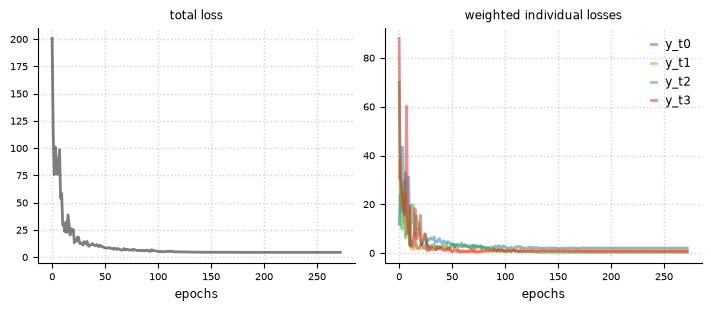

In [12]:
fit.plot.loss(figsize=(7, 3))

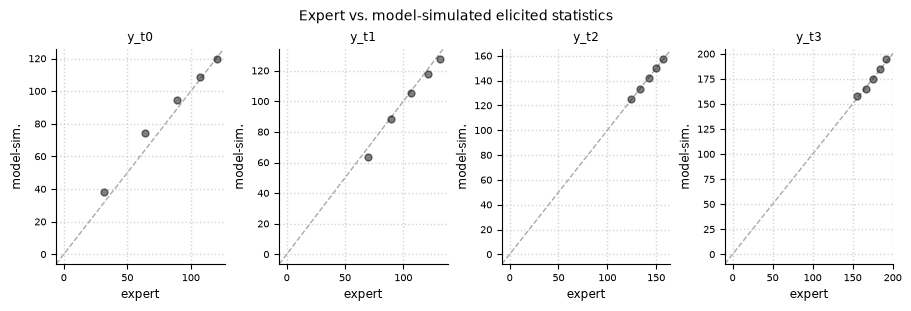

In [13]:
fit.plot.elicits(cols=4, figsize=(9, 3))

The parameters of interest are $h_{t_s}$, $h_1$, $s_0$, $s_1$ and $t_s$.
The model does not sample $h_1$ and $s_1$; it computes them from the two
differences. `el.utils.add_derived` writes both back into the prior samples,
so the plot can select them by name.

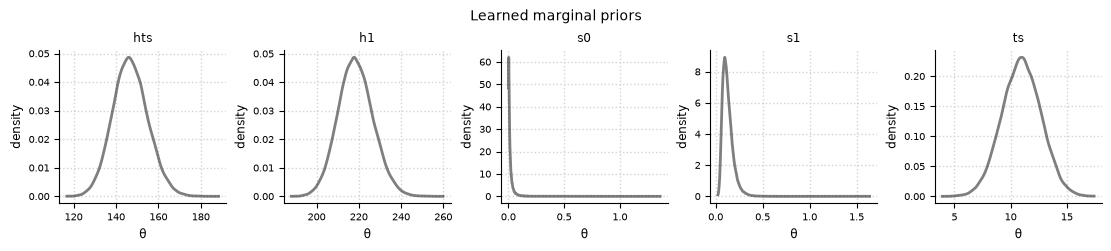

In [14]:
PARAMS_OF_INTEREST = ["hts", "h1", "s0", "s1", "ts"]


def add_h1_s1(draws):
    """Add the derived parameters h1 and s1 to the prior samples."""
    el.utils.add_derived(
        draws,
        h1=lambda prior: prior["hts"] + prior["dh"],
        s1=lambda prior: prior["s0"] + prior["ds"],
    )


add_h1_s1(samples)
fit.plot.prior_marginals(params=PARAMS_OF_INTEREST, cols=5, figsize=(11, 2.4))

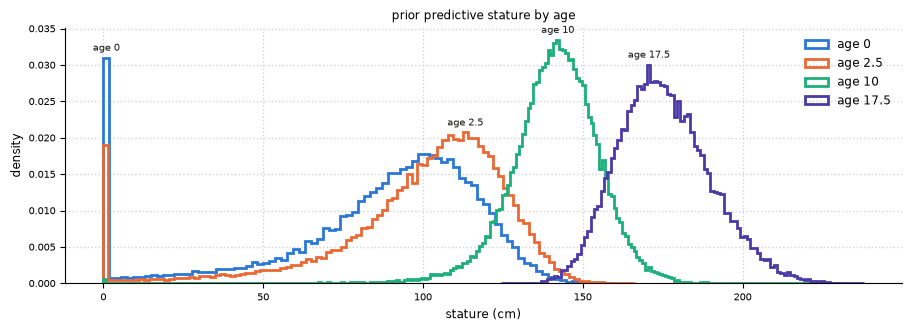

In [15]:
import matplotlib.pyplot as plt

TARGETS = ["y_t0", "y_t1", "y_t2", "y_t3"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]


def predictive(name):
    """Return the prior predictive draws of one target."""
    return (
        samples["target_quantity"][name]
        .to_dataset()
        .stack(stacked=("batch", "draw"))
        .to_array()
        .values[0, 0, :]
    )


fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for name, age, color in zip(TARGETS, AGES.numpy(), COLORS):
    counts, edges, _ = ax.hist(
        predictive(name),
        bins="auto",
        density=True,
        histtype="step",
        linewidth=2,
        color=color,
        label=f"age {age:g}",
    )
    mid = 0.5 * (edges[:-1] + edges[1:])
    ax.annotate(
        f"age {age:g}",
        (mid[counts.argmax()], counts.max()),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center",
        fontsize="x-small",
        color="#1a1a19",
    )

ax.set_xlabel("stature (cm)", fontsize="small")
ax.set_ylabel("density", fontsize="small")
ax.set_title("prior predictive stature by age", fontsize="small")
ax.legend(fontsize="small", frameon=False)
ax.grid(color="lightgrey", linestyle="dotted", linewidth=1)
ax.set_axisbelow(True)
ax.spines[["right", "top"]].set_visible(False)
ax.tick_params(labelsize="x-small")

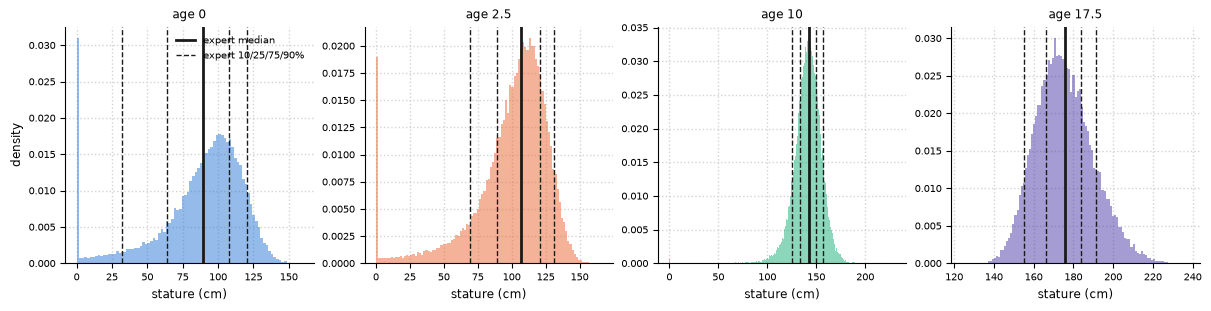

In [16]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for ax, name, age, color in zip(axes, TARGETS, AGES.numpy(), COLORS):
    ax.hist(
        predictive(name),
        bins="auto",
        density=True,
        color=color,
        alpha=0.5,
        edgecolor="none",
    )
    expert_quantiles = fit.results.oracle.sel(replication=0)[name].values[0]
    for q, x in zip(QUANTILES, expert_quantiles):
        ax.axvline(
            x,
            color="#1a1a19",
            linewidth=2 if q == MEDIAN else 1,
            linestyle="solid" if q == MEDIAN else "dashed",
        )
    ax.set_title(f"age {age:g}", fontsize="small")
    ax.set_xlabel("stature (cm)", fontsize="small")
    ax.grid(color="lightgrey", linestyle="dotted", linewidth=1)
    ax.set_axisbelow(True)
    ax.spines[["right", "top"]].set_visible(False)
    ax.tick_params(labelsize="x-small")

axes[0].set_ylabel("density", fontsize="small")
axes[0].legend(
    handles=[
        Line2D([0], [0], color="#1a1a19", lw=2, label="expert median"),
        Line2D(
            [0], [0], color="#1a1a19", lw=1, ls="dashed", label="expert 10/25/75/90%"
        ),
    ],
    fontsize="x-small",
    frameon=False,
)

## The same fit, with a gradient

Adam is the alternative. It uses the same seed and the same 400 prior
draws. Adam needs a start value, so a CMA-ES search of 300 evaluations over
the box runs first. The CMA-ES run has no search before it.

The budget is not the same work, and the two numbers are not comparable.
For Adam, 800 epochs are 800 gradient steps, and each step is one forward
pass **and** one backward pass. For CMA-ES, 3000 is the number of forward
simulations.

`decay_steps` matches the number of epochs. The schedule then spans the
whole run, as it did at the shorter budget.

Adam needs two settings that the search does not need: a learning rate
schedule, and `clipnorm`. Without them the run dies with a loss that is not
finite.

In [17]:
eliobj_adam = el.Elicit(
    model,
    targets,
    parameters,
    initializer=el.initializer(method="cmaes", distribution=BOX, iterations=300),
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=tf.keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=0.01, decay_steps=800, decay_rate=0.02
        ),
        clipnorm=1.0,
    ),
    seeds=(2025,),
    epochs=800,
    num_samples=400,
    verbose=False,
)

start = time.time()
fit_adam = eliobj_adam.fit(expert)
adam_seconds = time.time() - start

In [18]:
def report(obj, label, seconds):
    """Print the final loss, the learned growth spurt, and the run time."""
    loss = obj.results["history_stats/loss"]["total_loss"].values[0]
    # the history stores the constrained value, so a_ts is already in years
    ts = obj.results["history_stats/hyperparameter"]["a_ts"].values[0]
    print(
        f"{label:5s}: {len(loss):3d} points, final loss {loss[-1]:8.2f},"
        f" best loss {loss.min():8.2f}, ts {ts[-1]:5.2f} years,"
        f" {seconds:5.0f} s"
    )


report(fit, "cmaes", cma_seconds)
report(fit_adam, "adam", adam_seconds)

cmaes: 273 points, final loss     4.48, best loss     4.48, ts 10.96 years,    31 s
adam : 800 points, final loss    16.85, best loss    16.85, ts  4.06 years,    23 s


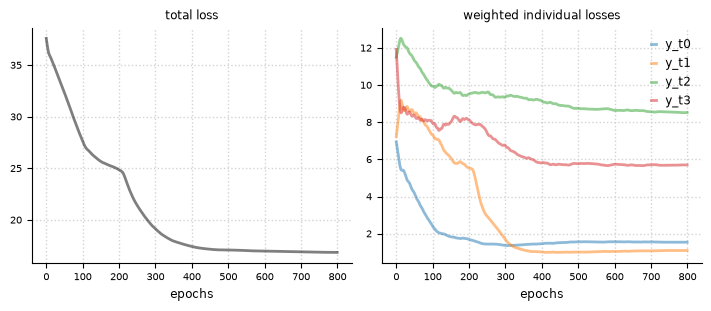

In [19]:
fit_adam.plot.loss(figsize=(7, 3))

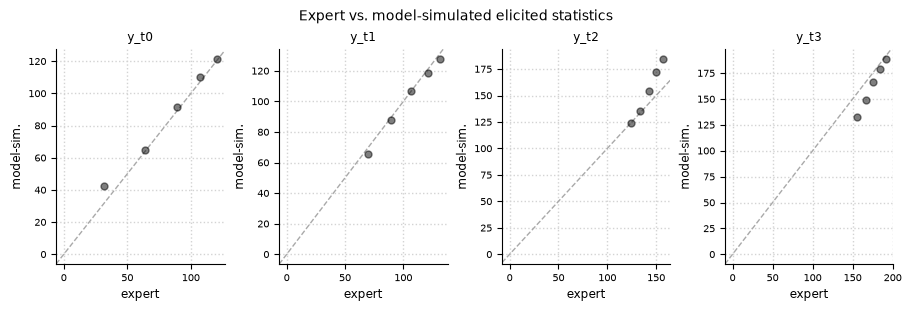

In [20]:
samples_adam = fit_adam.sample()
fit_adam.plot.elicits(cols=4, figsize=(9, 3))

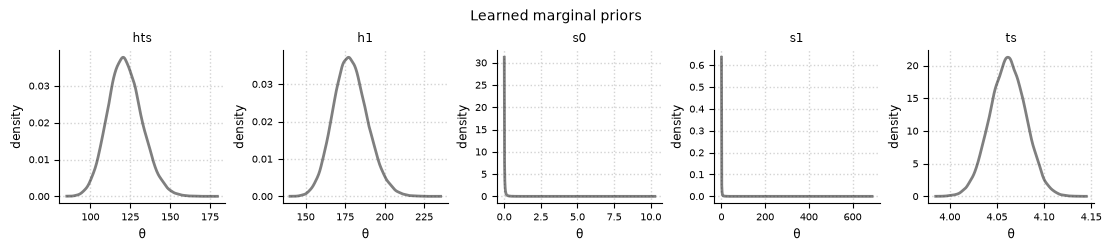

In [21]:
add_h1_s1(samples_adam)
fit_adam.plot.prior_marginals(params=PARAMS_OF_INTEREST, cols=5, figsize=(11, 2.4))

## Five experts

The paper reports five users. Table 1 of the paper gives user 1, and
tables 1 to 4 of the supplement give users 2 to 5. `PREDICTIVE_PRIOR`
above already holds the five columns, and `oracle(user)` turns one column
into a ground truth. So this section needs no new data.

The five users do not agree:

- user 1 expects an adult height of 174.5 cm, and the spurt at 13.4 years.
- user 2 expects the tallest adult, 191.7 cm, and the latest spurt, at 15.9
  years. Its $b = 61.4$ is the largest of the five, so user 2 states the
  smallest spread around one stature, 2.1%.
- user 3 expects 177.1 cm, and the earliest spurt, at 11.3 years.
- users 4 and 5 expect 174.5 and 174.4 cm, and the spurt at 14.7 and 14.6
  years. User 4 is almost certain of $h_{t^*}$ and $h_1$, and user 5 of
  $t^*$ and $s_1$.

Every fit uses the same design, the same start point and the same budget.
Only the expert changes.

One fit is one sample of one search. We repeat it five times, with a
different seed each time. The five runs then separate two effects. A
difference between two experts is the expert. A difference between two runs
of the same expert is the search.

`seeds` runs the five replications, and `elicito` stores them
in the `replication` dimension of `fit.results`.

In [22]:
USERS = (1, 2, 3, 4, 5)
USER_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#4a3aa7", 5: "#e34948"}
REPLICATIONS = 5
SEEDS = [2025, 2026, 2027, 2028, 2029]


def fit_user(user):
    """Fit the growth model to the prior of one user, five times."""
    obj = el.Elicit(
        model,
        targets,
        parameters,
        cmaes={"sigma0": 1.0},
        seeds=tuple(SEEDS),
        epochs=3000,
        num_samples=400,
        verbose=False,
    )
    return obj.fit(el.expert.simulator(ground_truth=oracle(user), num_samples=10_000))


fits = {u: fit_user(u) for u in USERS}

## Did the search converge?

The best loss of each run is the first check. A run with a large loss did
not fit, and it says nothing about its expert. A spread over the five runs
of one expert is the search, not the expert.

The loss curves show the five runs of each expert. A curve that is still
falling at the last epoch did not converge. A flat curve at a high loss
ended in a worse optimum than the other runs.

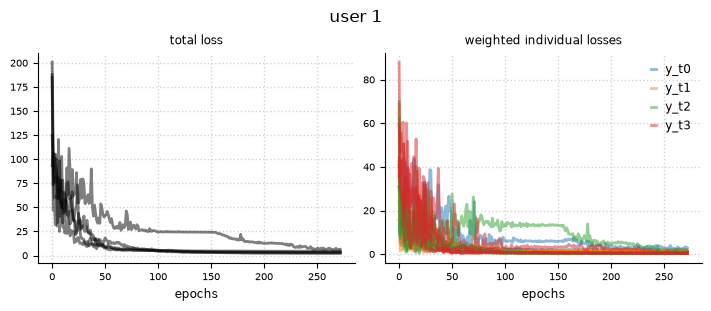

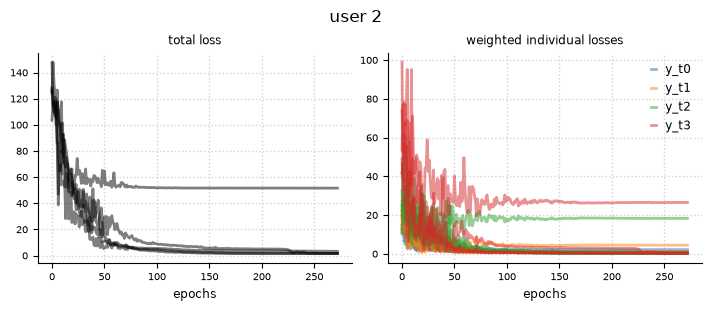

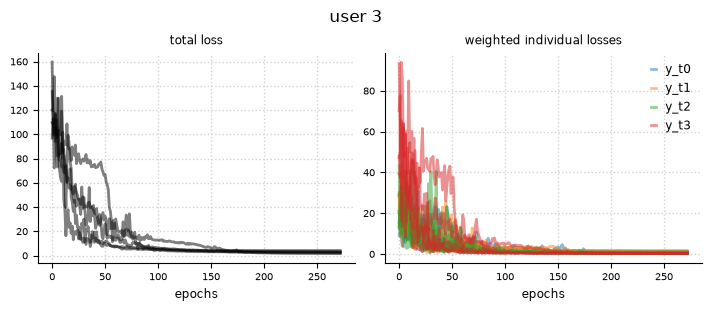

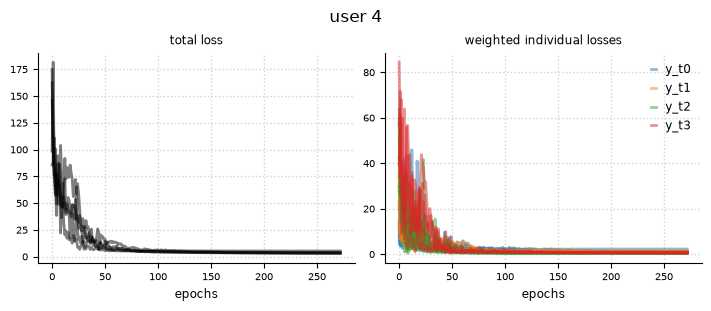

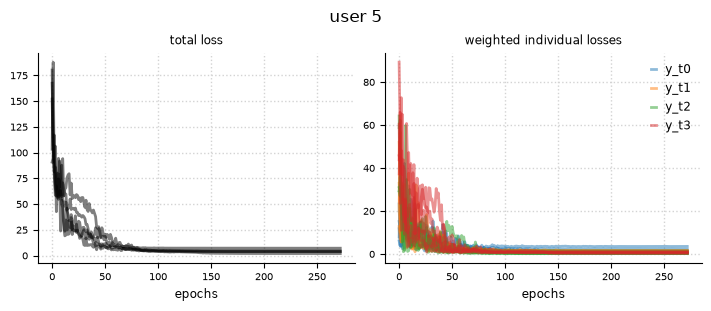

In [23]:
for u in USERS:
    fig, _ = fits[u].plot.loss(figsize=(7, 3))
    fig.suptitle(f"user {u}")

In [24]:
samples_user = {u: fits[u].sample() for u in USERS}


def successful(draws):
    """Return the replications whose simulated elicits are finite."""
    summary = draws["elicited_summary"]
    return [
        i
        for i in range(summary.sizes["replication"])
        if all(
            np.isfinite(summary.sel(replication=i)[name].values).all()
            for name in summary.data_vars
        )
    ]


print(f"{'user':>5s}  best loss of each of the {REPLICATIONS} runs")
for u in USERS:
    loss = fits[u].results["history_stats/loss"]["total_loss"].values
    print(
        f"{u:5d} "
        + " ".join(f"{np.nanmin(loss[i]):8.2f}" for i in successful(samples_user[u]))
    )

 user  best loss of each of the 5 runs
    1     4.48     2.06     3.15     5.72     3.23
    2     1.67     1.61    45.71     3.26     1.66
    3     1.73     4.19     2.20     3.30     2.70
    4     3.80     5.35     3.28     3.92     3.00
    5     7.26     4.92     4.09     3.96     2.10


## Read the fit in the elicit space

We do **not** compare the learned prior with the prior of the oracle. The
six parameters are not identified. The section on the model above names two
directions in which the prediction does not change: $s_0$ and $s_1$ near
zero, where $\delta_h$ drops out of the curve, and $s_0$ above the overflow
of `exp`, where every value gives the same curve. A distance in the
parameter space therefore says nothing about the quality of a fit.

The fit is judged where the expert spoke. The expert states five quantiles
at each of the four ages, so twenty numbers. The model simulates the same
twenty numbers. A point on the diagonal is a match.

One row is one expert, and one column is one age. Each row holds the five
runs of that expert.

Text(0.5, 0.98, 'expert-elicited and model-simulated quantiles (cm)')

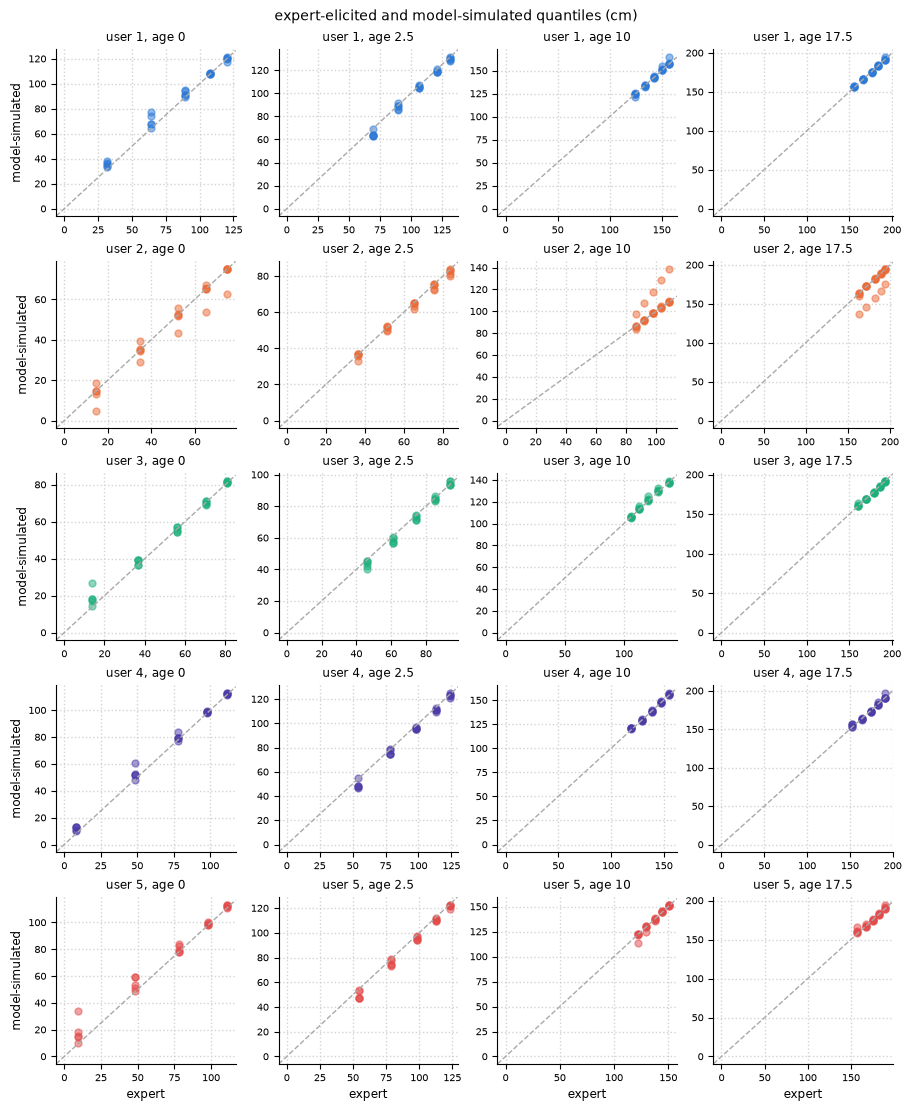

In [25]:
fig, axes = plt.subplots(
    len(USERS), len(TARGETS), figsize=(9, 2.2 * len(USERS)), constrained_layout=True
)
for row, u in zip(axes, USERS):
    res = fits[u].results
    summary = samples_user[u]["elicited_summary"]
    for ax, name, age in zip(row, TARGETS, AGES.numpy()):
        for i in successful(samples_user[u]):
            expert_q = res.oracle.sel(replication=i)[name].values[0]
            model_q = summary.sel(replication=i)[name].values.mean(axis=0)
            ax.plot(expert_q, model_q, "o", ms=5, alpha=0.5, color=USER_COLORS[u])
        ax.axline((0, 0), slope=1, color="darkgrey", linestyle="dashed", lw=1)
        ax.set_title(f"user {u}, age {age:g}", fontsize="small")
        ax.grid(color="lightgrey", linestyle="dotted", linewidth=1)
        ax.set_axisbelow(True)
        ax.spines[["right", "top"]].set_visible(False)
        ax.tick_params(labelsize="x-small")
    row[0].set_ylabel("model-simulated", fontsize="small")
for ax in axes[-1]:
    ax.set_xlabel("expert", fontsize="small")
fig.suptitle("expert-elicited and model-simulated quantiles (cm)", fontsize="medium")